## Name : Ishant Mishra

## Data Exploration and pre-processing

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("insurance.csv")

In [4]:
df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [5]:
print("Shape:",df.shape)

Shape: (1338, 7)


In [7]:
print("Columns:",df.columns)

Columns: Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')


In [8]:
print(df.dtypes)

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


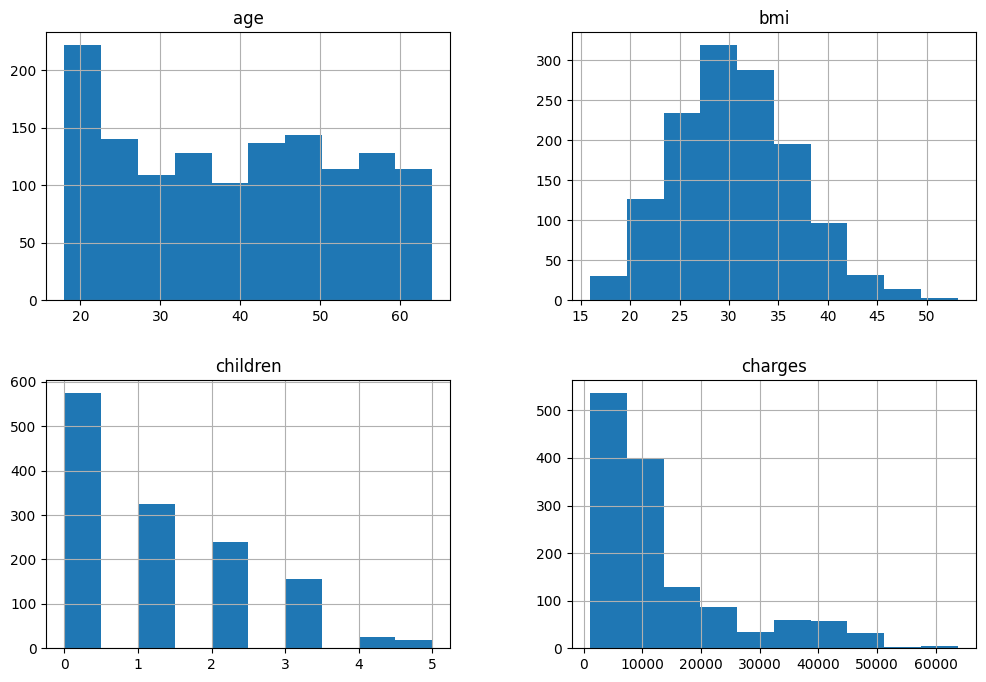

In [11]:
df.hist(figsize=(12,8))
plt.show()

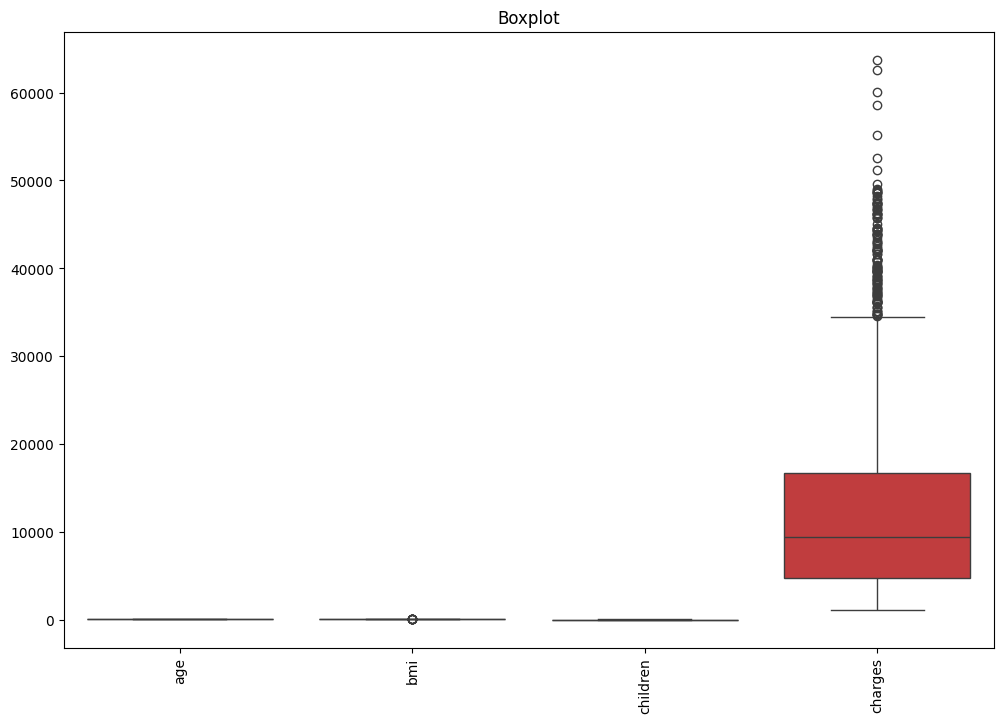

In [ ]:
#BoxPlot
plt.figure(figsize=(12,8))
sns.boxplot(data = df)
plt.xticks(rotation=90)
plt.title("Boxplot")
plt.show()

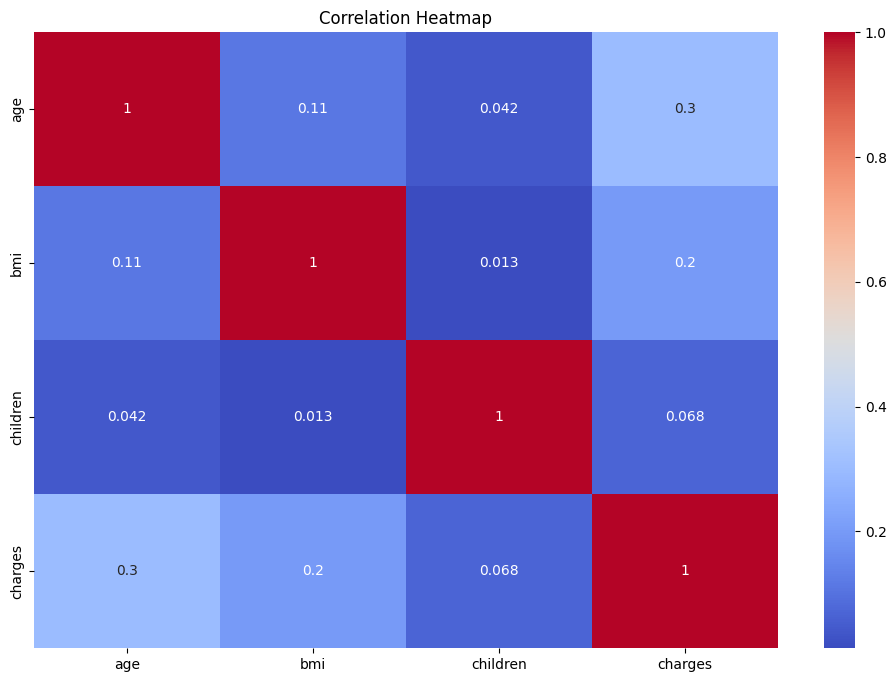

In [18]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [19]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

## outlier detection (IQR method)

In [22]:
df_numeric = df.select_dtypes(include=[np.number])
Q1 = df_numeric.quantile(0.25)
Q3 = df_numeric.quantile(0.75)
IQR = Q3 - Q1

df_clean = df[~((df_numeric < (Q1 - 1.5 * IQR)) | (df_numeric > (Q3 + 1.5 * IQR))).any(axis=1)]

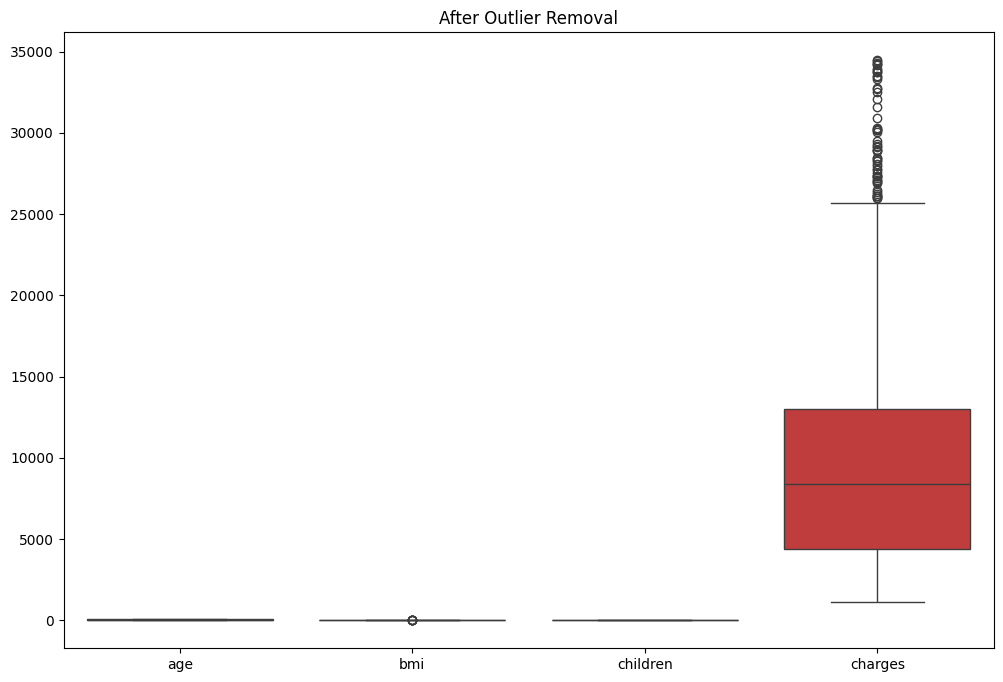

In [24]:
plt.figure(figsize=(12,8))
sns.boxplot(data=df_clean)
plt.title("After Outlier Removal")
plt.show()

## Encoding catagorical variable

In [25]:
df_clean = pd.get_dummies(df_clean, drop_first=True)

## Feature scaling

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df_clean)

df_scaled = pd.DataFrame(scaled_data, columns=df_clean.columns)

In [29]:
df.to_csv("pre-processed_data.csv")